In [ ]:
import socket
import time
import csv
import struct
import json
from tqdm import tqdm

HOST = 'localhost'
PORT = 18871
CSV_FILE = '../data/paths/1_TheRightWay.csv'
OUTPUT_JSONL = '../data/dataAug19/1_Quasi_Static_Log.jsonl'

feedback_bytes = 37 * 8

def recv_all(sock, nbytes):
    """Receive exactly nbytes from socket."""
    data = b''
    while len(data) < nbytes:
        packet = sock.recv(nbytes - len(data))
        if not packet:
            return None
        data += packet
    return data

# Connect to Simulink TCP server
sock = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
sock.connect((HOST, PORT))
print(f"Connected to {HOST}:{PORT}")

Connected to localhost:18871


In [ ]:
previous_command = [0.0] * 6  # Initialize previous command

with open(CSV_FILE, newline='') as csvfile, open(OUTPUT_JSONL, 'w') as jsonl_file:
    reader = list(csv.reader(csvfile))  # Convert to list for tqdm progress bar

    for row in tqdm(reader, desc="Processing commands"):
        if len(row) != 6:
            continue

        try:
            command = [float(val) for val in row]
        except ValueError:
            continue

        # Send command (6 doubles)
        msg = struct.pack('<6d', *command)
        sock.sendall(msg)

        # Compute sum of absolute differences
        delta_sum = sum(abs(c - p) for c, p in zip(command, previous_command))
        previous_command = command

        # Conditional wait
        time.sleep(5.0 if delta_sum > 5 else 1.5)

        # Clear buffer (non-blocking read to flush)
        sock.setblocking(0)
        try:
            while True:
                sock.recv(1024)
        except BlockingIOError:
            pass
        sock.setblocking(1)

        # Read feedback (37 doubles)
        data = recv_all(sock, feedback_bytes)
        if data is None:
            print("Connection closed by Simulink")
            break

        feedback = struct.unpack('<37d', data)

        X_Pos = list(feedback[0:6])
        FRaw = list(feedback[6:12])
        FF_EE = list(feedback[12:18])
        FF_GB = list(feedback[18:24])
        Foot_Pedal = feedback[24]
        X_Dot_Commands = list(feedback[25:31])
        X_DoubleDot_Commands = list(feedback[31:37])

        # Write one JSON object per line
        jsonl_file.write(json.dumps({
            "X_Pos": X_Pos,
            "FRaw": FRaw,
            "FF_EE": FF_EE,
            "FF_GB": FF_GB,
            "Foot_Pedal": Foot_Pedal,
            "X_Dot_Cmds": X_Dot_Commands,
            "X_DoubleDot_Cmds": X_DoubleDot_Commands
        }) + '\n')

print("All commands sent. Closing connection.")
sock.close()
print(f"Log saved to {OUTPUT_JSONL}")


Processing commands:  57%|█████▋    | 208/363 [03:33<02:39,  1.03s/it]


KeyboardInterrupt: 

In [ ]:
import json
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error

# === Load data ===
data = []
with open(OUTPUT_JSONL, 'r') as f:
    for line in f:
        data.append(json.loads(line))
print(f"Loaded {len(data)} records.")

# === Extract features: Orientation angles ===
X = np.array([[entry['X_Pos'][3], entry['X_Pos'][4], entry['X_Pos'][5]] for entry in data])  # rx, ry, rz

# === Target: full FF_EE vector (force + torque) ===
y = np.array([entry['FF_EE'][:6] for entry in data])  # FF_EE[0:6]

# === Train/test split ===
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# === Create pipeline ===
degree = 3
model = Pipeline([
    ('poly', PolynomialFeatures(degree)),
    ('regressor', MultiOutputRegressor(LinearRegression()))
])
model.fit(X_train, y_train)

# === Evaluate ===
y_pred = model.predict(X_test)
total_mse = mean_squared_error(y_test, y_pred)
print(f"Total MSE (FF_EE[0:6]): {total_mse:.6f}")

for i in range(6):
    mse_i = mean_squared_error(y_test[:, i], y_pred[:, i])
    print(f"FF_EE[{i}] MSE: {mse_i:.6f}")


Loaded 362 records.
Total MSE (FF_EE[0:6]): 0.000872
FF_EE[0] MSE: 0.002040
FF_EE[1] MSE: 0.000159
FF_EE[2] MSE: 0.003024
FF_EE[3] MSE: 0.000003
FF_EE[4] MSE: 0.000005
FF_EE[5] MSE: 0.000001


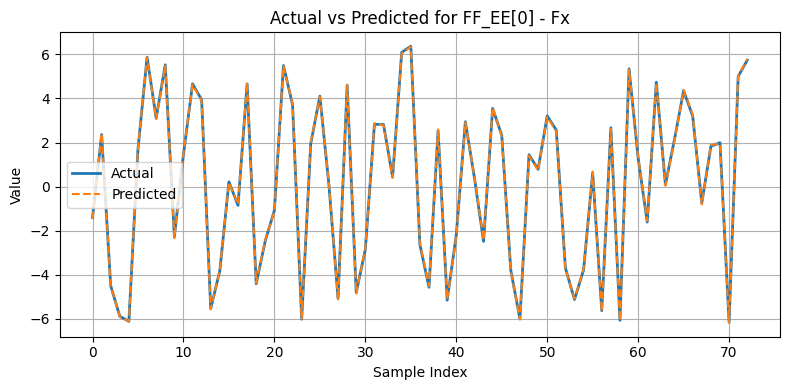

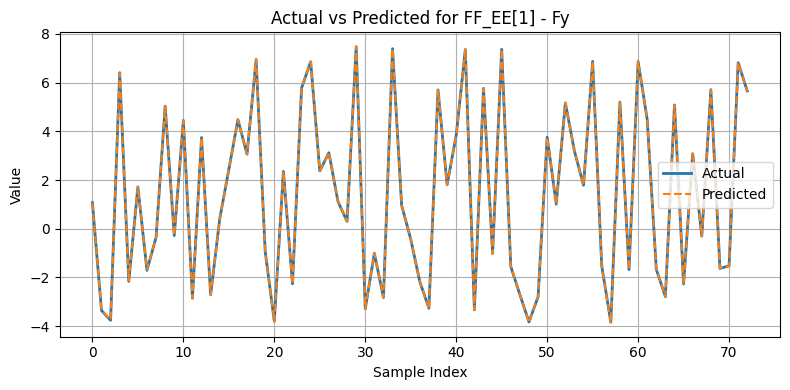

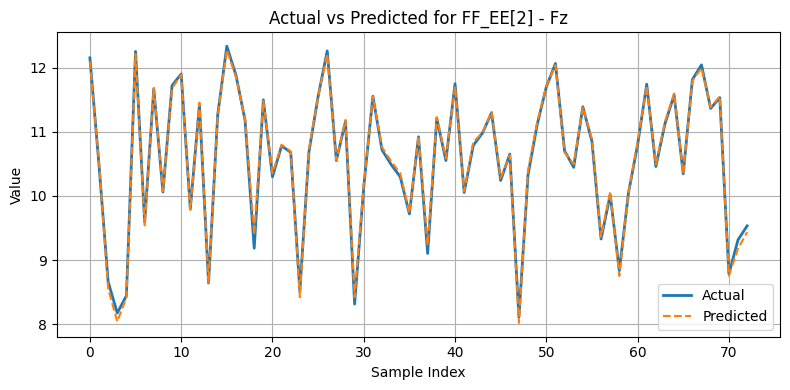

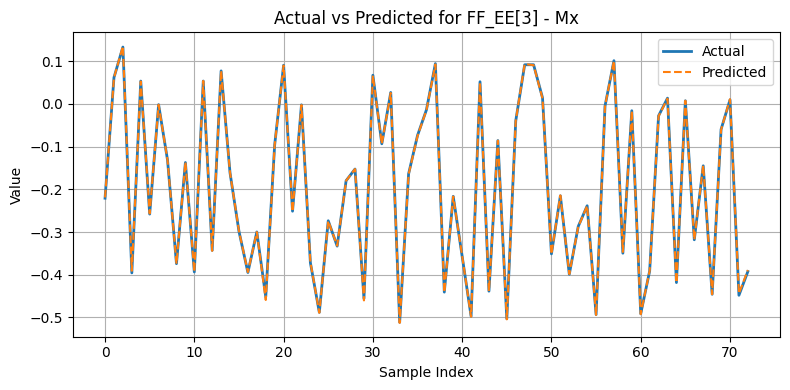

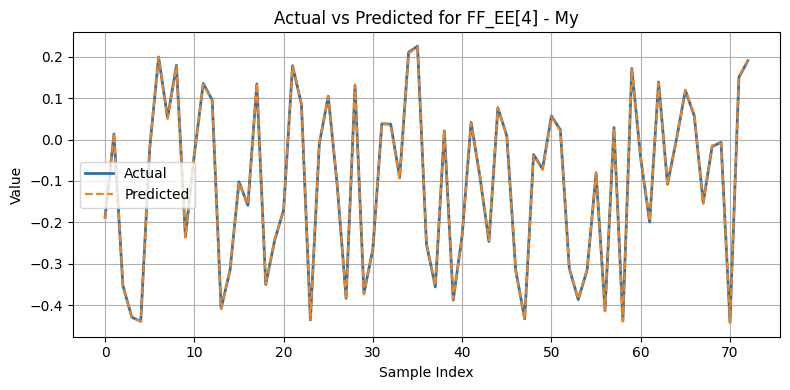

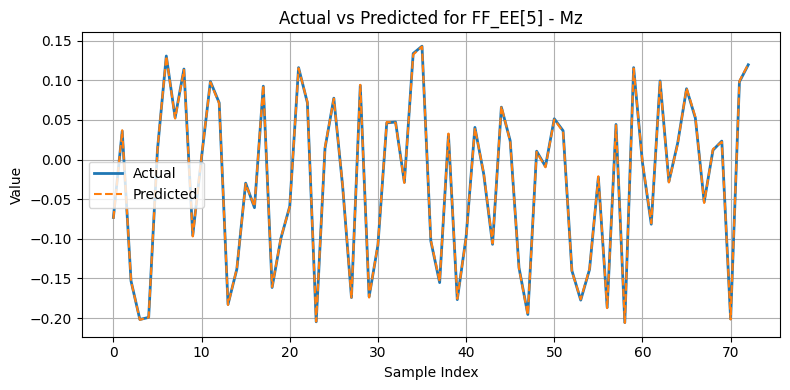

In [ ]:
import matplotlib.pyplot as plt

# Number of points to plot
N = 100
subset_indices = np.arange(min(N, len(X_test)))

# Updated labels for all 6 components
component_labels = [
    'FF_EE[0] - Fx',
    'FF_EE[1] - Fy',
    'FF_EE[2] - Fz',
    'FF_EE[3] - Mx',
    'FF_EE[4] - My',
    'FF_EE[5] - Mz'
]

# Plot all components
for i in range(6):
    plt.figure(figsize=(8, 4))
    plt.plot(subset_indices, y_test[subset_indices, i], label='Actual', linewidth=2)
    plt.plot(subset_indices, y_pred[subset_indices, i], label='Predicted', linestyle='--')
    plt.title(f'Actual vs Predicted for {component_labels[i]}')
    plt.xlabel('Sample Index')
    plt.ylabel('Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [ ]:
import os
import joblib
# === Save model ===
os.makedirs('../models/dataAug19', exist_ok=True)
joblib.dump(model, '../models/dataAug19/1_Quasi_Static_Poly.pkl')
print("Model saved to ../models/dataAug19/1_Quasi_Static_Poly.pkl")


Model saved to ../paper/models/1_Quasi_Static_Poly5.pkl


In [2]:
# export_poly_model_to_mat.py
import joblib, numpy as np
from scipy.io import savemat
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

PKL = r"../models/dataAug19/1_Quasi_Static_Poly.pkl"  # <-- your saved model
MAT = r"poly_model_params.mat"

def unwrap(model):
    """Return (poly, scaler, reg) regardless of pipeline/plain layout."""
    poly = None
    scaler = None
    reg = None

    if isinstance(model, Pipeline):
        for name, step in model.named_steps.items():
            if isinstance(step, PolynomialFeatures):
                poly = step
            elif isinstance(step, StandardScaler):
                scaler = step
            elif hasattr(step, "coef_") and hasattr(step, "intercept_"):
                reg = step
    else:
        # Plain regressor (no pipeline)
        if hasattr(model, "coef_") and hasattr(model, "intercept_"):
            reg = model

    if reg is None:
        raise ValueError("Could not find a fitted regressor with coef_ / intercept_.")
    return poly, scaler, reg

def export_to_mat(pkl_path, mat_path):
    model = joblib.load(pkl_path)
    poly, scaler, reg = unwrap(model)

    # Coefficients/orientation: MATLAB will compute y = COEF @ phi + INTERCEPT
    # scikit shapes: coef_: (n_outputs, n_poly_features), intercept_: (n_outputs,)
    coef = reg.coef_.astype(np.float32, copy=False)
    if coef.ndim == 1:
        coef = coef.reshape(1, -1)  # single-output
    intercept = reg.intercept_.astype(np.float32, copy=False).reshape(-1, 1)

    # Polynomial powers: powers_[i, j] = exponent of feature j in monomial i
    if poly is None:
        raise ValueError("PolynomialFeatures step not found. "
                         "This exporter expects a fitted PolynomialFeatures.")
    if not hasattr(poly, "powers_"):
        raise ValueError("PolynomialFeatures does not have powers_. Make sure it's fitted.")
    powers = poly.powers_.astype(np.int32, copy=False)  # (n_phi, n_features)
    n_phi, n_feat = powers.shape

    # Optional input scaler
    if scaler is not None and hasattr(scaler, "mean_") and hasattr(scaler, "scale_"):
        mu = scaler.mean_.astype(np.float32, copy=False).reshape(-1, 1)            # (n_feat,1)
        invsigma = (1.0 / scaler.scale_).astype(np.float32, copy=False).reshape(-1, 1)
    else:
        mu = np.zeros((n_feat, 1), dtype=np.float32)
        invsigma = np.ones((n_feat, 1), dtype=np.float32)

    # Sanity prints
    print("coef", coef.shape, "intercept", intercept.shape)
    print("powers", powers.shape, "mu", mu.shape, "invsigma", invsigma.shape)

    savemat(mat_path, {
        "COEF": coef,             # (n_out, n_phi) float32
        "INTERCEPT": intercept,   # (n_out, 1)     float32
        "POWERS": powers,         # (n_phi, n_feat) int32
        "MU": mu,                 # (n_feat, 1)    float32
        "INVSIGMA": invsigma,     # (n_feat, 1)    float32
    })
    print(f"Saved {mat_path}")

if __name__ == "__main__":
    export_to_mat(PKL, MAT)


FileNotFoundError: [Errno 2] No such file or directory: '../models/dataAug19/1_Quasi_Static_Poly.pkl'